## Shear accuracy: selection bias analysis
Invesigates how galaxy properties compare between BATSim and GalSim

now with $\pm g$ simulations

In [19]:
import os
os.environ['OMP_NUM_THREADS'] = '1'

import galsim
import batsim
import anacal
import numpy as np
import matplotlib.pyplot as plt
import pickle

from tqdm import tqdm
from importlib import reload
reload(batsim)

base_path = '/home/nep151/github/BATSim/notebooks/validation'
set_paths = {'+': f'{base_path}/COSMOS_lensed_nov',
             '-': f'{base_path}/COSMOS_lensed_nov_neg'}


Main dict for feeding to the generators, these values must match 

In [20]:
np.random.seed(14)
config_dict = {
    'scale': 0.2,
    'nn': 96,
    'lens_shear': 0.025,
    'lens_shear2': 0.015,
    'n_rot': 4,
    'n_gal_stamp': 1600,
    'tiles_per_side': 40,
    'psf_beta': 3.5,
    'psf_fwhm':0.7,
    'noise_variance': 0.23
}
cosmos = galsim.COSMOSCatalog()
print(f'Catalog size: {len(cosmos)}')
len_cosmos = len(cosmos)
n_stamps = int(np.ceil(len_cosmos / config_dict['n_gal_stamp']))
all_inds = np.arange(len_cosmos)
stamp_inds = np.array_split(all_inds, n_stamps)

psf       = galsim.Moffat(beta=config_dict['psf_beta'], fwhm=config_dict['psf_fwhm'])
psf_array = psf.drawImage(nx=config_dict['nn'], ny=config_dict['nn'], scale=config_dict['scale']).array

Catalog size: 81499


In [21]:
all_gal_inds = np.concatenate(stamp_inds)
all_records  = cosmos.getParametricRecord(index=all_gal_inds)

mag_all      = all_records['mag_auto']
hlr_all      = all_records['hlr'][:, 0]          # half-light radius [arcsec]
sersic_n_all = all_records['sersicfit'][:, 2]    # Sersic index
is_bulgefit  = all_records['use_bulgefit'].astype(bool)

stamp_offsets = np.concatenate([[0], np.cumsum([len(s) for s in stamp_inds])])

print(f'Total galaxies  : {len(all_gal_inds)}')
print(f'mag range       : [{mag_all.min():.1f}, {mag_all.max():.1f}]')
print(f'hlr range       : [{hlr_all.min():.3f}, {hlr_all.max():.3f}] arcsec')
print(f'sersic_n range  : [{sersic_n_all.min():.1f}, {sersic_n_all.max():.1f}]')
print(f'bulge+disk frac : {is_bulgefit.mean():.2%}')

Total galaxies  : 81499
mag range       : [16.7, 25.2]
hlr range       : [0.000, 7.827] arcsec
sersic_n range  : [0.1, 6.0]
bulge+disk frac : 28.74%


### Next section is a bunch of helper functions

In [22]:
def measure_shear(gal_array, psf_array, npix, pixel_scale, noise_variance, noise_array, detection):
    """
    Measure shear using the FPFS estimator via anacal.

    Parameters
    ----------
    gal_array : np.ndarray
        2D galaxy image array.
    psf_array : np.ndarray
        2D PSF image array.
    npix : int
        Individual galaxy stamp size in pixels, used for shapelet basis operations.
    pixel_scale : float
        Pixel scale in arcsec/pixel.
    noise_variance : float
        Noise variance of the image. A minimum floor of 0.23 is applied internally.
    noise_array : np.ndarray or None
        2D noise image array, or None if not available.
    detection : np.ndarray or None
        Structured array with fields ('y', 'x') giving pre-specified detection
        positions. If None, FPFS auto-detection is run.

    Returns
    -------
    np.ndarray
        Structured array containing per-galaxy FPFS measurements, including
        fields such as 'fpfs_w', 'fpfs_e1', 'fpfs_de1_dg1', 'fpfs_dw_dg1'.
    """
    fpfs_config = anacal.fpfs.FpfsConfig(
        sigma_shapelets=0.52,
        sigma_shapelets2=0.45,
        npix=npix
    )
    catalog = anacal.fpfs.process_image(
        fpfs_config=fpfs_config,
        mag_zero=30.0,
        gal_array=gal_array,
        psf_array=psf_array,
        pixel_scale=pixel_scale,
        noise_variance=max(noise_variance, 0.23),
        noise_array=noise_array,
        detection=detection,
    )
    return catalog

def jk_err(A):
    A = np.asarray(A)
    n = len(A)
    return np.sqrt((n-1)/n * np.sum((A - A.mean()) ** 2))

def tile_sums(catalogs, cat_gal_k, comp, galaxy_mask=None):
    """
    Per-stamp sums of the FPFS shear estimator for component comp (1 or 2).

    galaxy_mask : bool array over all galaxies (len(all_gal_inds)), or None for all.
    Returns E, R arrays of length n_stamps.
    """
    E = np.zeros(len(catalogs))
    R = np.zeros(len(catalogs))
    for i, (cat, k) in enumerate(zip(catalogs, cat_gal_k)):
        sel = slice(None) if galaxy_mask is None else galaxy_mask[stamp_offsets[i] + k]
        w, e = cat['fpfs_w'][sel], cat[f'fpfs_e{comp}'][sel]
        E[i] = np.sum(w * e)
        R[i] = np.sum(cat[f'fpfs_dw_dg{comp}'][sel] * e
                      + w * cat[f'fpfs_de{comp}_dg{comp}'][sel])
    return E, R

def paired_estimate(Ep, Rp, Em, Rm, g_true):
    """m and c from +g and -g sums (works on scalars or leave-one-out arrays)."""
    R = Rp + Rm
    return (Ep - Em) / R / g_true - 1, (Ep + Em) / R


def jackknife_pm(Ep, Rp, Em, Rm, g_true):
    """Paired +/- estimator with stamp jackknife (same stamp dropped from both sets)."""
    m, c = paired_estimate(Ep.sum(), Rp.sum(), Em.sum(), Rm.sum(), g_true)
    m_loo, c_loo = paired_estimate(Ep.sum() - Ep, Rp.sum() - Rp,
                                   Em.sum() - Em, Rm.sum() - Rm, g_true)
    return {'m': m, 'm_err': jk_err(m_loo), 'c': c, 'c_err': jk_err(c_loo),
            'm_loo': m_loo, 'c_loo': c_loo,
            # unpaired per-set shear estimates, for sanity checks
            'g_plus': Ep.sum() / Rp.sum(), 'g_minus': Em.sum() / Rm.sum()}

def compute_bias_for_mask(galaxy_mask=None, comp=1):
    """
    Paired m and c for GalSim and BATSim, plus BT - GS differences.

    Returns dict with keys 'gs', 'bt' (jackknife_pm dicts), 'dm', 'dm_err',
    'dc', 'dc_err', or None if the selection has zero total response.
    """
    g_true = config_dict['lens_shear' if comp == 1 else 'lens_shear2']
    res = {}
    for sim in ('gs', 'bt'):
        Ep, Rp = tile_sums(cats['+'][f'{sim}_catalogs'], cats['+']['cat_gal_k'], comp, galaxy_mask)
        Em, Rm = tile_sums(cats['-'][f'{sim}_catalogs'], cats['-']['cat_gal_k'], comp, galaxy_mask)
        if Rp.sum() + Rm.sum() == 0:
            return None
        res[sim] = jackknife_pm(Ep, Rp, Em, Rm, g_true)
    for q in ('m', 'c'):
        res[f'd{q}']     = res['bt'][q] - res['gs'][q]
        res[f'd{q}_err'] = jk_err(res['bt'][f'{q}_loo'] - res['gs'][f'{q}_loo'])  # paired
    return res


In [23]:
POS_Y = 'y'
POS_X = 'x'


def detection_to_galaxy_k(cat, nn, n_rot, tiles_per_side=40):
    """
    Reverse-map auto-detected source positions to local galaxy indices.

    Each galaxy occupies a tile of size (nn * sqrt(n_rot)) pixels. Integer
    division of the detected position by that tile size gives the galaxy index k.

    Parameters
    ----------
    cat : np.ndarray
        Structured catalog with position fields POS_Y and POS_X.
    nn : int
        Individual rotation sub-stamp size in pixels (e.g. 96).
    n_rot : int
        Number of shape-noise cancellation rotations per galaxy (e.g. 4).
    tiles_per_side : int, optional
        Number of galaxy tiles per side of the large stamp. Default is 40.

    Returns
    -------
    np.ndarray of int
        Local galaxy index k (0-indexed within the stamp) for each catalog entry.
    """
    ts = int(nn * np.sqrt(n_rot))
    y  = cat[POS_Y].astype(int)
    x  = cat[POS_X].astype(int)
    return (y // ts) * tiles_per_side + (x // ts)


def detection_to_rot_k(cat, nn, rot_per_side=80):
    """
    Map auto-detected source positions to rotation sub-stamp indices.

    Each rotation sub-stamp occupies an nn × nn pixel area. This is used for
    deduplication at the sub-stamp level so that all n_rot rotations of a
    galaxy are preserved while genuine double-detections within one sub-stamp
    are removed.

    Parameters
    ----------
    cat : np.ndarray
        Structured catalog with position fields POS_Y and POS_X.
    nn : int
        Rotation sub-stamp size in pixels (e.g. 96).
    rot_per_side : int, optional
        Number of rotation sub-stamps per side of the large stamp.
        Default is 80 (= 40 galaxy tiles × 2 sub-stamps per side per tile).

    Returns
    -------
    np.ndarray of int
        Rotation sub-stamp index for each catalog entry.
    """
    y = cat[POS_Y].astype(int)
    x = cat[POS_X].astype(int)
    return (y // nn) * rot_per_side + (x // nn)

In [24]:
def keep_one_per_tile(cat, k_array):
    """
    Retain only the first detection per tile.

    Used at the rotation sub-stamp level (96×96) to remove genuine double-peaks
    within one sub-stamp while preserving all n_rot rotations per galaxy.

    Parameters
    ----------
    cat : np.ndarray
        Structured catalog array to filter.
    k_array : np.ndarray of int
        Tile index for each entry in cat.

    Returns
    -------
    cat_filtered : np.ndarray
        Catalog with at most one entry per unique tile.
    k_filtered : np.ndarray of int
        Corresponding tile indices for the filtered catalog.
    """
    _, first_idx = np.unique(k_array, return_index=True)
    first_idx = np.sort(first_idx)
    return cat[first_idx], k_array[first_idx]

In [25]:
def build_catalog(catalog_path, config_dict, stamp_inds, psf_array, version):
    nn = config_dict['nn']
    n_rot = config_dict['n_rot']
    tiles_per_side = config_dict['tiles_per_side']
    scale = config_dict['scale']
    stamp_size = int(nn * np.sqrt(n_rot * config_dict['n_gal_stamp']))
    rot_per_side = tiles_per_side * int(np.sqrt(n_rot))   # 40 * 2 = 80

    out = dict(gs_catalogs=[], bt_catalogs=[], cat_gal_k=[], 
               gs_only_k_list=[], bt_only_k_list=[], neither_k_list=[])

    for i in tqdm(range(len(stamp_inds)), desc=os.path.basename(catalog_path)):
    # v4: dedup at rotation sub-stamp level to preserve all n_rot rotations per galaxy
        cache_file = os.path.join(catalog_path, f'fpfs_autodet_cat_{version}_{i}.pkl')
        n_gal = len(stamp_inds[i])

        if os.path.exists(cache_file):
            with open(cache_file, 'rb') as f:
                gs_cat, bt_cat, k, gs_only_k, bt_only_k, neither_k = pickle.load(f)
        else:
            gs_cat, bt_cat = [
                measure_shear(
                gal_array=galsim.fits.read(file_name=os.path.join(
                    catalog_path, f'{sim}_stamp_{i}_{stamp_size}x{stamp_size}.fits')).array,
                psf_array=psf_array, npix=nn, pixel_scale=scale, 
                noise_variance=config_dict['noise_variance'],
                noise_array=None, detection=None)
                for sim in ('galsim', 'batsim')]

            # Dedup at 96×96 rotation sub-stamp level — all n_rot rotations are kept
            k_rot_gs = detection_to_rot_k(gs_cat, nn, rot_per_side)
            k_rot_bt = detection_to_rot_k(bt_cat, nn, rot_per_side)
            gs_cat, k_rot_gs = keep_one_per_tile(gs_cat, k_rot_gs)
            bt_cat, k_rot_bt = keep_one_per_tile(bt_cat, k_rot_bt)

            # Map to galaxy-level index for filtering and matching
            k_gs = detection_to_galaxy_k(gs_cat, nn, n_rot, tiles_per_side)
            k_bt = detection_to_galaxy_k(bt_cat, nn, n_rot, tiles_per_side)

            # Drop detections outside valid galaxy tiles
            valid_gs = k_gs < n_gal
            gs_cat, k_rot_gs, k_gs = gs_cat[valid_gs], k_rot_gs[valid_gs], k_gs[valid_gs]
            valid_bt = k_bt < n_gal
            bt_cat, k_rot_bt, k_bt = bt_cat[valid_bt], k_rot_bt[valid_bt], k_bt[valid_bt]

            # Match at rotation sub-stamp level — guarantees identical catalog lengths
            common_rot = np.array(sorted(set(k_rot_gs) & set(k_rot_bt)))
            gs_mask = np.isin(k_rot_gs, common_rot)
            bt_mask = np.isin(k_rot_bt, common_rot)

            # Sort by rotation sub-stamp index so entry j is the same rotation in both catalogs
            gs_ord = np.argsort(k_rot_gs[gs_mask])
            bt_ord = np.argsort(k_rot_bt[bt_mask])
            gs_cat = gs_cat[gs_mask][gs_ord]
            bt_cat = bt_cat[bt_mask][bt_ord]
            k      = k_gs[gs_mask][gs_ord]   # galaxy index per matched rotation sub-stamp

            # Detection categories at galaxy level
            k_gs_set = set(k_gs)
            k_bt_set = set(k_bt)
            gs_only_k = np.array(sorted(k_gs_set - k_bt_set))
            bt_only_k = np.array(sorted(k_bt_set - k_gs_set))
            neither_k = np.setdiff1d(np.arange(n_gal), np.union1d(k_gs, k_bt))

            with open(cache_file, 'wb') as f:
                pickle.dump((gs_cat, bt_cat, k, gs_only_k, bt_only_k, neither_k), f)

        for key, val in zip(out, (gs_cat, bt_cat, k, gs_only_k, bt_only_k, neither_k)):
            out[key].append(val)
    
    n_total = sum(len(s) for s in stamp_inds)
    for label, n in [('Matched (both)',   sum(len(np.unique(k)) for k in out['cat_gal_k'])),
                     ('GalSim only',      sum(len(x) for x in out['gs_only_k_list'])),
                     ('BATSim only',      sum(len(x) for x in out['bt_only_k_list'])),
                     ('Neither detected', sum(len(x) for x in out['neither_k_list']))]:
        print(f'{label:<17}: {n:6d}  ({n/n_total:.1%})')


    return out


In [26]:
def collect_props(k_list):
    """
    Collect galaxy properties for a set of per-stamp local galaxy indices.

    Parameters
    ----------
    k_list : list of np.ndarray of int
        List of length n_stamps, where each element contains the local galaxy
        indices (k) within that stamp for the galaxies of interest.

    Returns
    -------
    dict
        Dictionary with keys:
        'mag'        : np.ndarray, AB magnitudes (mag_auto).
        'hlr'        : np.ndarray, half-light radii in arcsec.
        'sersic_n'   : np.ndarray, Sersic indices.
        'is_bulgefit' : np.ndarray of bool, True where a bulge+disk model was used.
    """
    mag, hlr, n_s, bulge = [], [], [], []
    for i, k_arr in enumerate(k_list):
        if len(k_arr) == 0:
            continue
        g_idx = stamp_offsets[i] + k_arr
        mag.append(mag_all[g_idx])
        hlr.append(hlr_all[g_idx])
        n_s.append(sersic_n_all[g_idx])
        bulge.append(is_bulgefit[g_idx])
    return {
        'mag':         np.concatenate(mag)   if mag   else np.array([]),
        'hlr':         np.concatenate(hlr)   if hlr   else np.array([]),
        'sersic_n':    np.concatenate(n_s)   if n_s   else np.array([]),
        'is_bulgefit': np.concatenate(bulge) if bulge else np.array([], dtype=bool),
    }

In [27]:
def run_binned_analysis(prop, bin_edges, label, comp=1, base_mask=None, min_gals=100):
    """
    Paired m and c for GalSim and BATSim in bins of a galaxy property.

    prop : array over all galaxies (same order as all_gal_inds)
    Bins are half-open [edge[i], edge[i+1]). Bins with < min_gals galaxies are NaN.
    """
    centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    n_bins  = len(centers)
    keys = [f'{q}_{sim}{e}' for q in ('m', 'c') for sim in ('gs', 'bt') for e in ('', '_err')] \
         + ['dm', 'dm_err', 'dc', 'dc_err']
    out = dict(centers=centers, bin_edges=bin_edges, comp=comp,
               n_gals=np.zeros(n_bins, dtype=int),
               **{k: np.full(n_bins, np.nan) for k in keys})

    for b in tqdm(range(n_bins), desc=f'{label} (g{comp})'):
        mask = (prop >= bin_edges[b]) & (prop < bin_edges[b + 1])
        if base_mask is not None:
            mask &= base_mask
        out['n_gals'][b] = mask.sum()
        if out['n_gals'][b] < min_gals:
            continue
        r = compute_bias_for_mask(mask, comp)
        if r is None:
            continue
        for q in ('m', 'c'):
            for sim in ('gs', 'bt'):
                out[f'{q}_{sim}'][b]     = r[sim][q]
                out[f'{q}_{sim}_err'][b] = r[sim][f'{q}_err']
            out[f'd{q}'][b], out[f'd{q}_err'][b] = r[f'd{q}'], r[f'd{q}_err']
    return out


In [32]:
def get_valid(res, ref_err, m_or_c='m', max_err_factor=5):
    """
    Build a boolean mask selecting bins with reliable bias estimates.

    Filters out bins where the jackknife error is more than max_err_factor
    times the full-sample reference error, which typically indicates too few
    galaxies for a stable estimate.

    Parameters
    ----------
    res : dict
        Output dict from run_binned_analysis.
    ref_err : float
        Full-sample jackknife error used as the reference scale.
    max_err_factor : float, optional
        Maximum allowed ratio of bin error to ref_err. Default is 5.

    Returns
    -------
    np.ndarray of bool
        True for bins that are not NaN and have errors within the threshold.
    """
    gs_key = m_or_c + '_gs'
    err_key = m_or_c + '_gs_err'
    bt_err_key = m_or_c + '_bt_err'
    return (
        ~np.isnan(res[gs_key])
        & (res[err_key] < max_err_factor * ref_err)
        & (res[bt_err_key] < max_err_factor * ref_err)
    )


def plot_selection_bias_summary(results_list, titles, xlabels, log_x_flags,
                                res_full_gs, res_full_bt, m_or_c='m', save_path=None, ylim=None):
    """
    Plot a bias vs galaxy property for multiple properties.

    Produces a 3-row × N-column figure where each column corresponds to one
    galaxy property. Row 0 shows m_gs and m_bt with full-sample reference
    bands, row 1 shows the difference Δm = m_bt - m_gs, and row 2 shows
    the number of galaxies per bin.

    Parameters
    ----------
    results_list : list of dict
        List of output dicts from run_binned_analysis, one per property.
    titles : list of str
        Column titles, one per property.
    xlabels : list of str
        x-axis labels, one per property.
    log_x_flags : list of bool
        If True, use a log x-axis for that column.
    res_full_gs : dict
        Full-sample jackknife result for GalSim (used for reference bands).
    res_full_bt : dict
        Full-sample jackknife result for BATSim (used for reference bands).
    save_path : str or None, optional
        If provided, save the figure to this path. Default is None.

    Returns
    -------
    None
    """
    
    
    fig, axes = plt.subplots(3, 3, figsize=(14, 10), sharey='row',
                             gridspec_kw={'height_ratios': [2, 1.5, 1]})
    if m_or_c == 'm':
        fig.suptitle('Multiplicative bias vs galaxy properties', fontsize=13)
    elif m_or_c == 'c':
        fig.suptitle('Addiative bias vs galaxy properties', fontsize=13)
    else:
        raise ValueError("you either should plot m or c")

    ref_lo = min((res_full_gs[m_or_c] - 3 * res_full_gs[m_or_c+'_err']) * 1e3,
                 (res_full_bt[m_or_c] - 3 * res_full_bt[m_or_c+'_err']) * 1e3)
    ref_hi = max((res_full_gs[m_or_c] + 3 * res_full_gs[m_or_c+'_err']) * 1e3,
                 (res_full_bt[m_or_c] + 3 * res_full_bt[m_or_c+'_err']) * 1e3)
    pad = abs(ref_hi - ref_lo)

    for col, (res, title, xlabel, log_x) in enumerate(
        zip(results_list, titles, xlabels, log_x_flags)
    ):
        valid  = get_valid(res, res_full_gs[m_or_c + '_err'], m_or_c=m_or_c)
        x      = res['centers'][valid]
        widths = np.diff(res['bin_edges'])[valid] * 0.6

        ax = axes[0, col]
        ax.axhspan((res_full_gs[m_or_c] - res_full_gs[m_or_c+'_err']) * 1e3,
                   (res_full_gs[m_or_c] + res_full_gs[m_or_c+'_err']) * 1e3,
                   alpha=0.1, color='C0', label='GalSim full-sample ±1σ')
        ax.axhspan((res_full_bt[m_or_c] - res_full_bt[m_or_c+'_err']) * 1e3,
                   (res_full_bt[m_or_c] + res_full_bt[m_or_c+'_err']) * 1e3,
                   alpha=0.1, color='C1', label='BATSim full-sample ±1σ')
        ax.errorbar(x, res[m_or_c+'_gs'][valid] * 1e3, yerr=res[m_or_c+'_gs_err'][valid] * 1e3,
                    fmt='o-', capsize=3, label='GalSim')
        ax.errorbar(x, res[m_or_c+'_bt'][valid] * 1e3, yerr=res[m_or_c+'_bt_err'][valid] * 1e3,
                    fmt='s-', capsize=3, label='BATSim')
        ax.axhline(0, color='k', ls='--', lw=0.8, alpha=0.5)
        ax.set_title(title)
        ax.set_ylim(*(ylim if ylim is not None else (ref_lo - pad, ref_hi + pad)))
        if col == 0:
            ax.set_ylabel(m_or_c+'  [×10⁻³]')
        ax.legend(fontsize=8)

        ax2 = axes[1, col]
        ax2.errorbar(x, res['d'+m_or_c][valid] * 1e3, yerr=res['d'+m_or_c+'_err'][valid] * 1e3,
                     fmt='D-', color='C2', capsize=3)
        ax2.axhline(0, color='k', ls='--', lw=0.8, alpha=0.5)
        if col == 0:
            if m_or_c == 'm':
                ax2.set_ylabel('Δm = m_bt − m_gs  [×10⁻³]')
            elif m_or_c == 'c':
                ax2.set_ylabel('Δc = c_bt − c_gs  [×10⁻³]')

        ax3 = axes[2, col]
        ax3.bar(x, res['n_gals'][valid], width=widths, color='gray', alpha=0.7)
        ax3.set_xlabel(xlabel)
        if col == 0:
            ax3.set_ylabel('N galaxies')

        if log_x:
            for ax_ in axes[:, col]:
                ax_.set_xscale('log')

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

### Now the actual running of the code:

In [28]:
cats = {sign: build_catalog(path, config_dict, stamp_inds, psf_array, version='v6')
        for sign, path in set_paths.items()}

COSMOS_lensed_nov: 100%|██████████| 51/51 [00:01<00:00, 44.68it/s]


Matched (both)   :  81437  (99.9%)
GalSim only      :      2  (0.0%)
BATSim only      :      0  (0.0%)
Neither detected :     60  (0.1%)


COSMOS_lensed_nov_neg: 100%|██████████| 51/51 [00:00<00:00, 118.07it/s]


Matched (both)   :  81437  (99.9%)
GalSim only      :      2  (0.0%)
BATSim only      :      0  (0.0%)
Neither detected :     60  (0.1%)


In [29]:
assert len(cats['+']['gs_catalogs']) == len(cats['-']['gs_catalogs']) == n_stamps

res_full = {comp: compute_bias_for_mask(comp=comp) for comp in (1, 2)}

for comp in (1, 2):
    g_true = config_dict['lens_shear' if comp == 1 else 'lens_shear2']
    r = res_full[comp]
    print(f'=== component {comp}  (true g{comp} = ±{g_true}) ===')
    for sim, name in [('gs', 'GalSim'), ('bt', 'BATSim')]:
        x = r[sim]
        print(f'{name:<7} ĝ+ = {x["g_plus"]:+.6f}  ĝ- = {x["g_minus"]:+.6f}  |  '
              f'm{comp} = {x["m"]:+.3e} ± {x["m_err"]:.1e}   '
              f'c{comp} = {x["c"]:+.3e} ± {x["c_err"]:.1e}')
    print(f'BT − GS            Δm{comp} = {r["dm"]:+.3e} ± {r["dm_err"]:.1e}   '
          f'Δc{comp} = {r["dc"]:+.3e} ± {r["dc_err"]:.1e}\n')


=== component 1  (true g1 = ±0.025) ===
GalSim  ĝ+ = +0.024987  ĝ- = -0.024987  |  m1 = -5.140e-04 ± 7.3e-04   c1 = -3.731e-12 ± 1.5e-11
BATSim  ĝ+ = +0.024993  ĝ- = -0.024993  |  m1 = -2.666e-04 ± 7.3e-04   c1 = +6.775e-11 ± 2.3e-11
BT − GS            Δm1 = +2.475e-04 ± 5.5e-05   Δc1 = +7.148e-11 ± 2.9e-11

=== component 2  (true g2 = ±0.015) ===
GalSim  ĝ+ = +0.014995  ĝ- = -0.014995  |  m2 = -3.002e-04 ± 8.5e-04   c2 = -7.301e-10 ± 5.8e-11
BATSim  ĝ+ = +0.014993  ĝ- = -0.014993  |  m2 = -4.868e-04 ± 8.6e-04   c2 = +3.779e-09 ± 2.4e-11
BT − GS            Δm2 = -1.866e-04 ± 5.7e-05   Δc2 = +4.509e-09 ± 6.6e-11



In [30]:
bin_specs = {
    'mag':      (mag_all,      np.array([18, 20, 21, 22, 23, 24, 25, 25.3]),             None),
    'sersic_n': (sersic_n_all, np.array([0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0]),      ~is_bulgefit),
    'hlr':      (hlr_all,      np.array([0.0, 0.1, 0.2, 0.3, 0.4, 0.6, 0.8, 1.2, 2.0]), None),
}

binned = {comp: {key: run_binned_analysis(prop, edges, key, comp, base_mask=base)
                 for key, (prop, edges, base) in bin_specs.items()}
          for comp in (1, 2)}

hlr (g2): 100%|██████████| 8/8 [00:00<00:00, 53.04it/s]


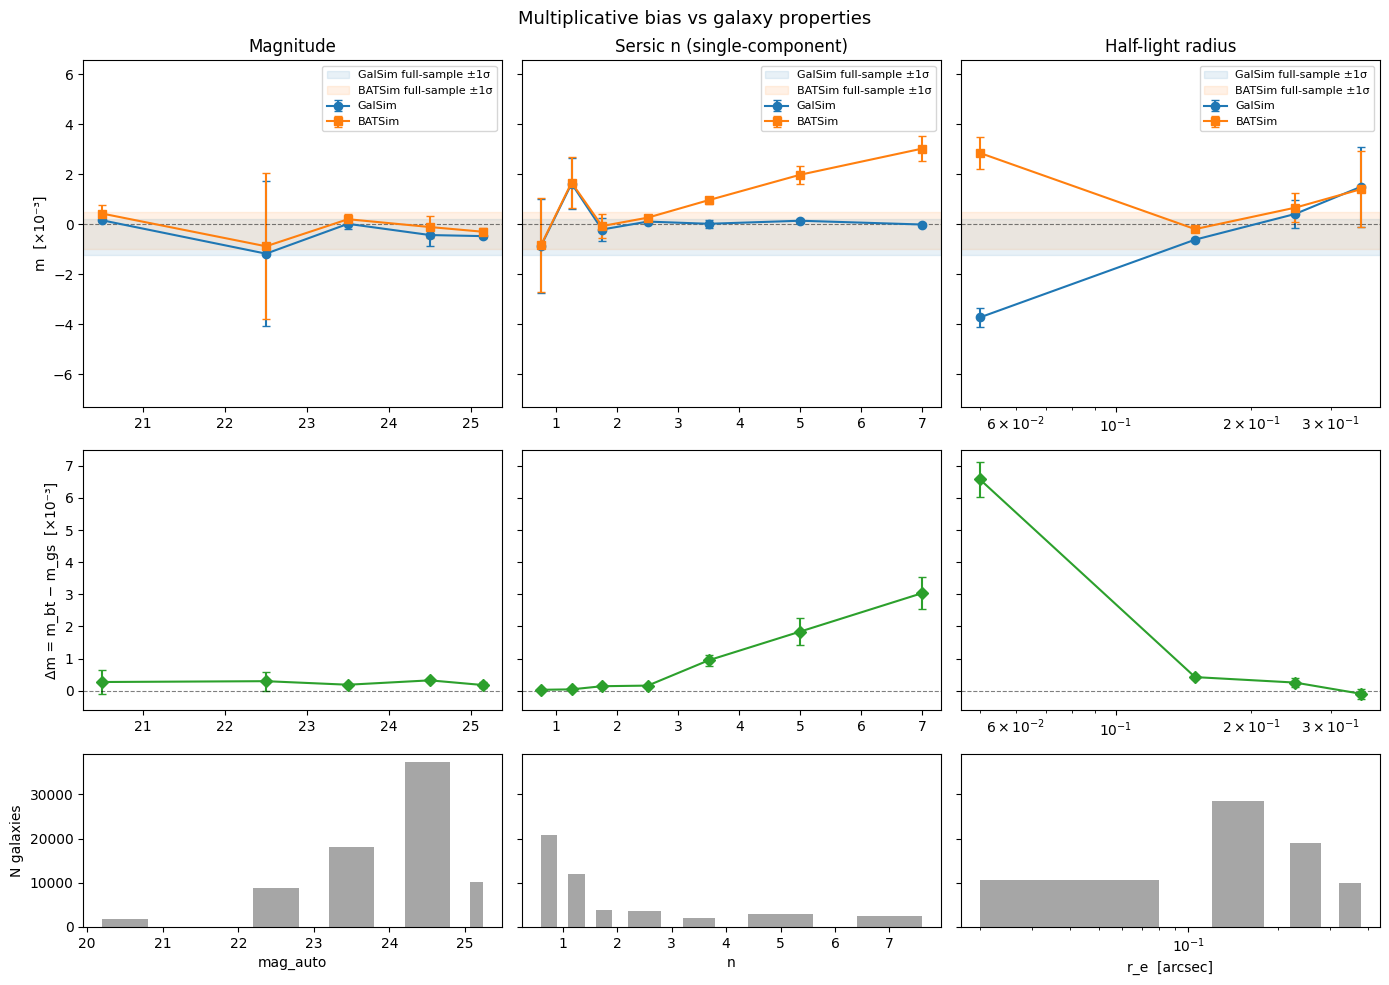

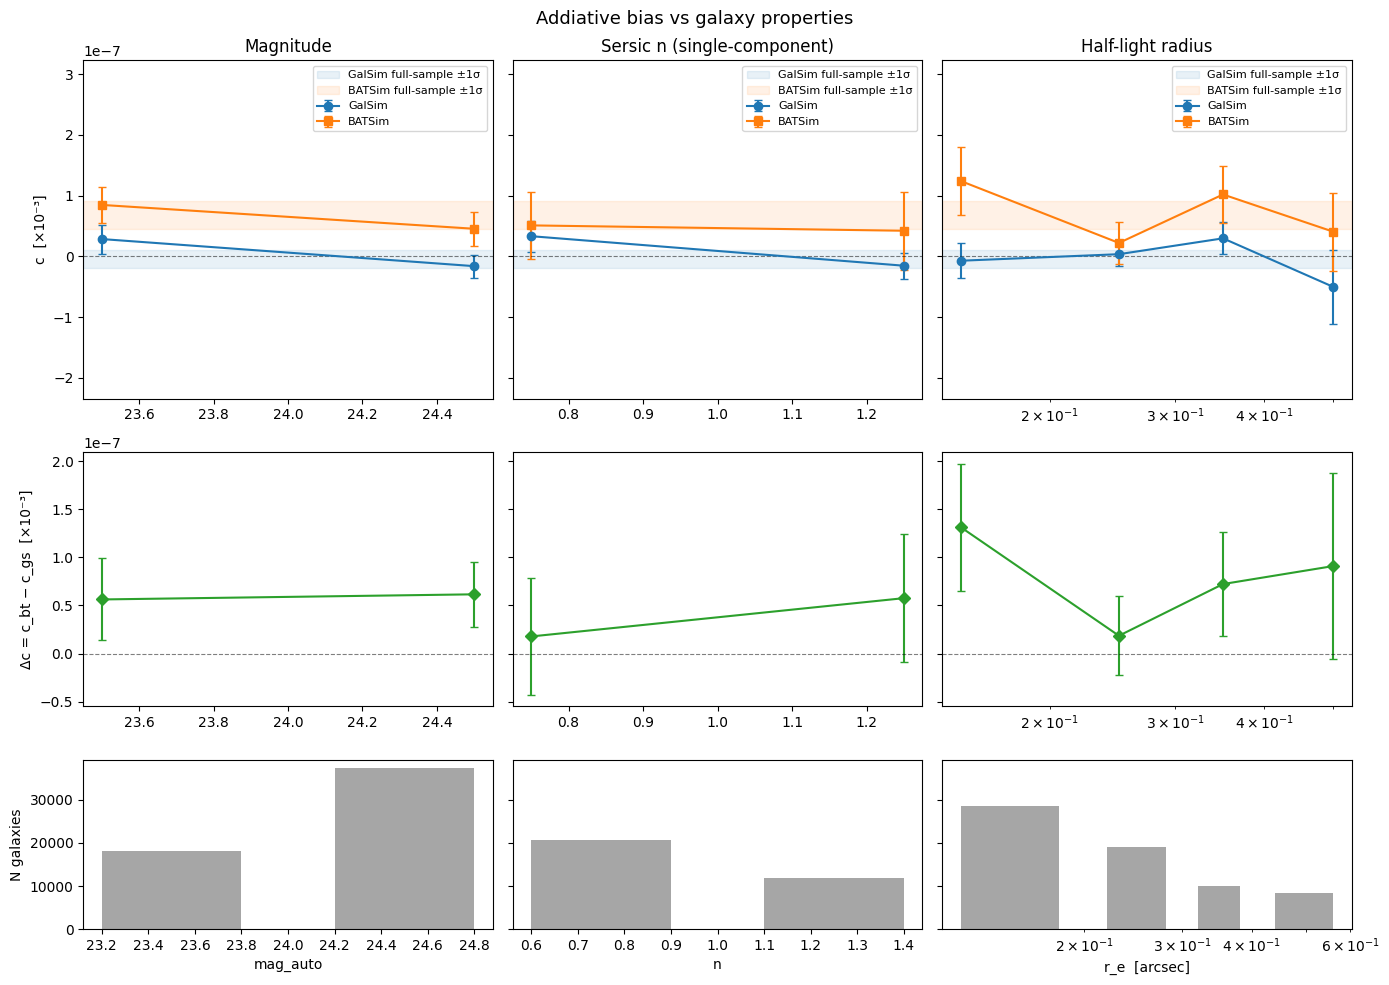

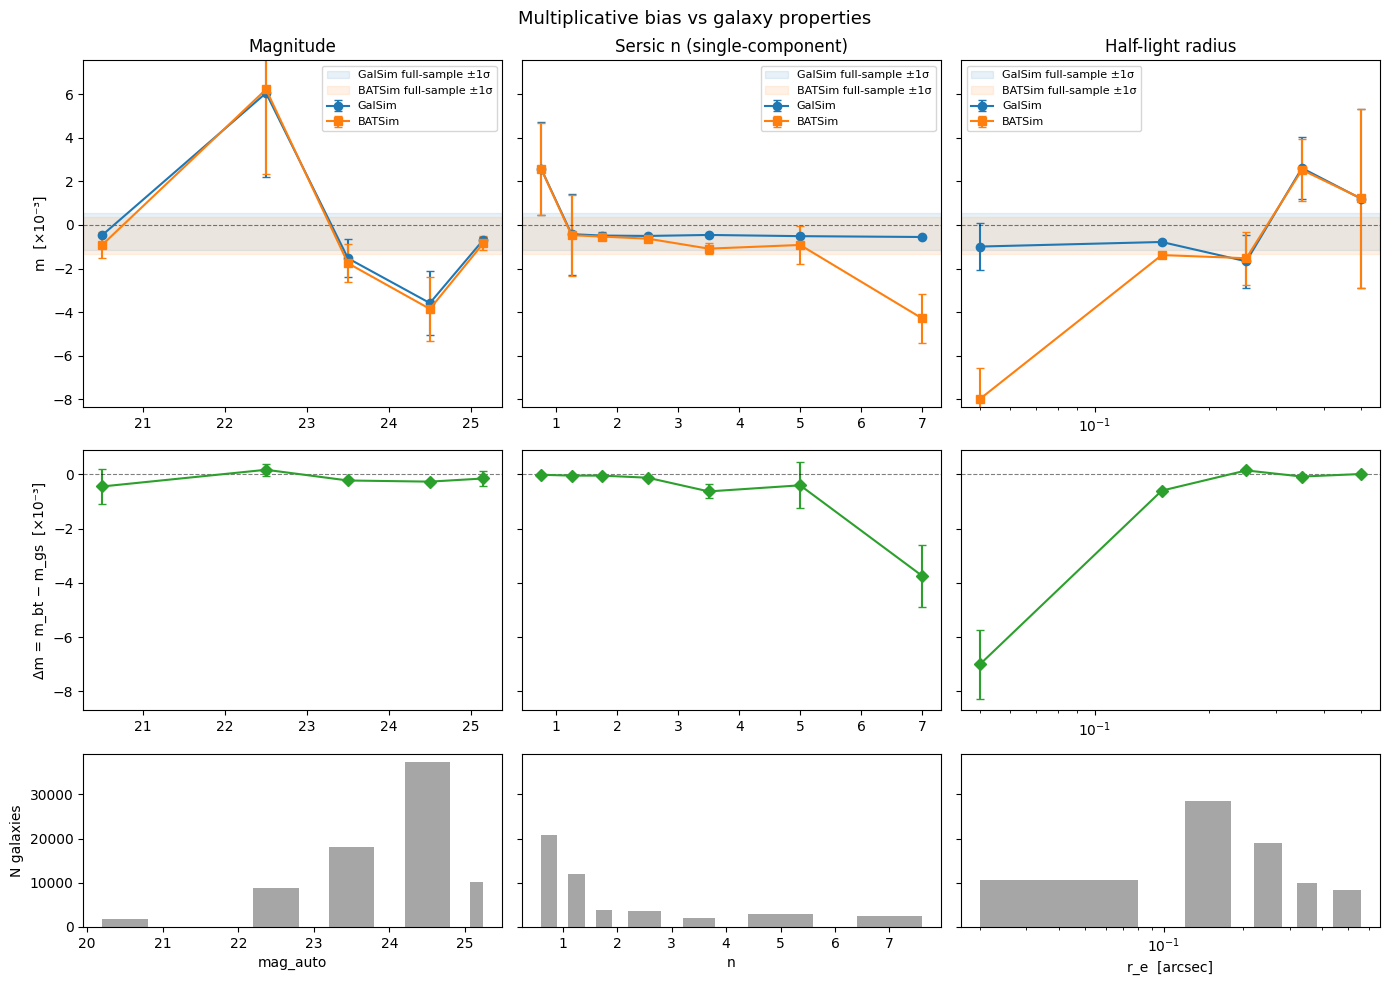

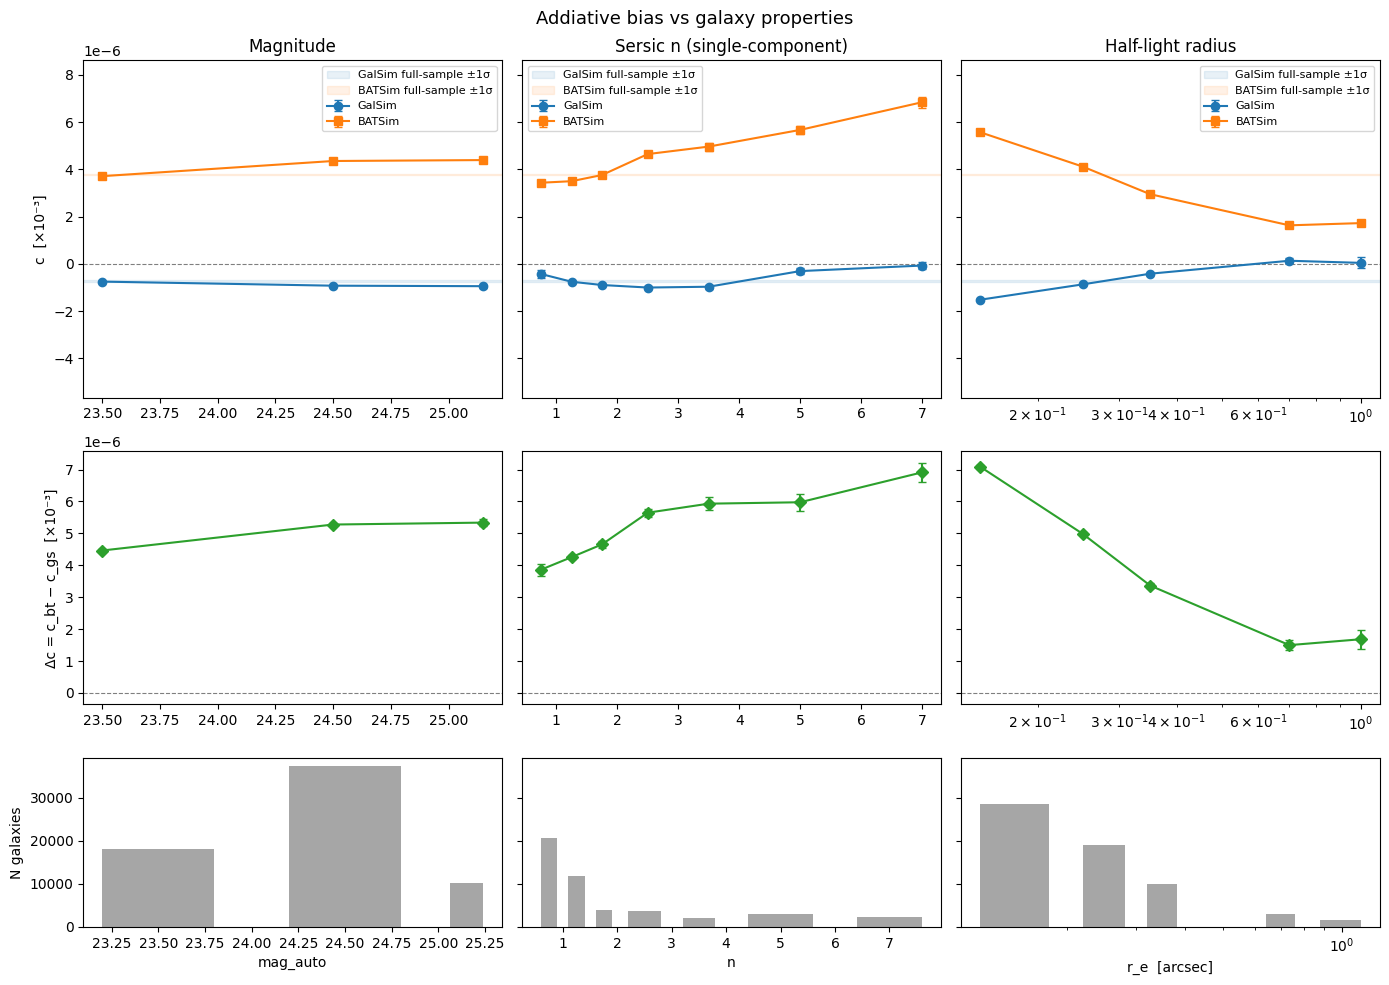

In [33]:
plot_cols = dict(
    titles      = ['Magnitude', 'Sersic n (single-component)', 'Half-light radius'],
    xlabels     = ['mag_auto',  'n',                           'r_e  [arcsec]'],
    log_x_flags = [False,       False,                         True],
)

for comp in (1, 2):
    for q in ('m', 'c'):
        plot_selection_bias_summary(
            results_list = [binned[comp][k] for k in ('mag', 'sersic_n', 'hlr')],
            res_full_gs  = res_full[comp]['gs'],
            res_full_bt  = res_full[comp]['bt'],
            m_or_c       = q,
            save_path    = f'pm_{q}{comp}_selection_bias_summary.png',
            **plot_cols,
        )
